Training files found: [PosixPath('/kaggle/input/competitions/playground-series-s4e4/train.csv')]
Testing files found: [PosixPath('/kaggle/input/competitions/playground-series-s4e4/test.csv')]
Training shape: (90615, 10)
Testing shape: (60411, 9)

First 5 lines of the training dataset:
   id Sex  Length  Diameter  Height  Whole weight  Whole weight.1  \
0   0   F   0.550     0.430   0.150        0.7715          0.3285   
1   1   F   0.630     0.490   0.145        1.1300          0.4580   
2   2   I   0.160     0.110   0.025        0.0210          0.0055   
3   3   M   0.595     0.475   0.150        0.9145          0.3755   
4   4   I   0.555     0.425   0.130        0.7820          0.3695   

   Whole weight.2  Shell weight  Rings  
0          0.1465        0.2400     11  
1          0.2765        0.3200     11  
2          0.0030        0.0050      6  
3          0.2055        0.2500     10  
4          0.1600        0.1975      9  

Correlation Matrix:
                  Length  Diamet

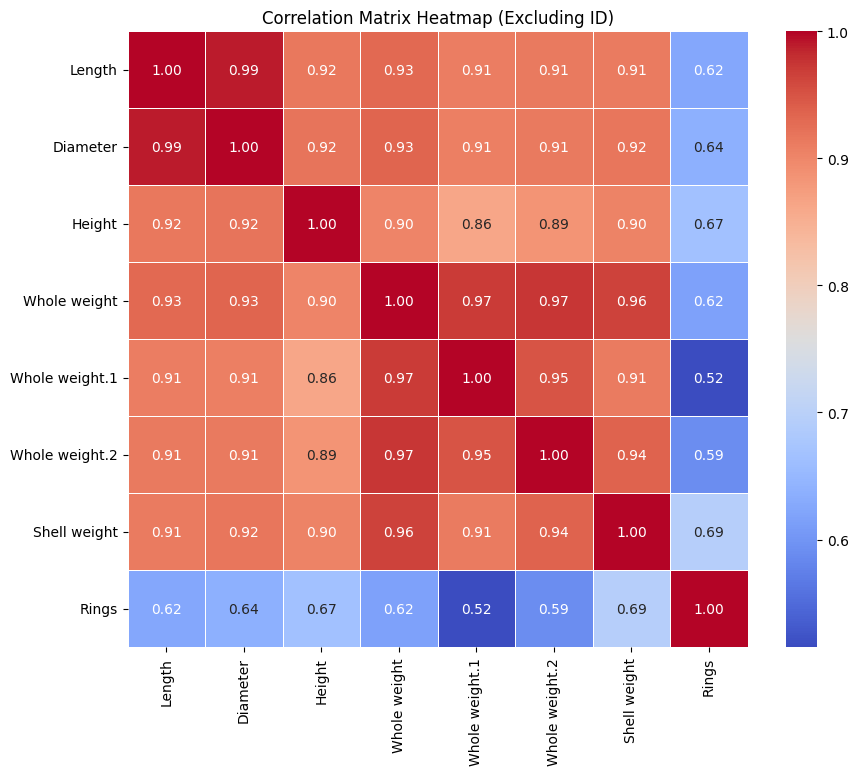


Generating pair plots for all numeric variables...


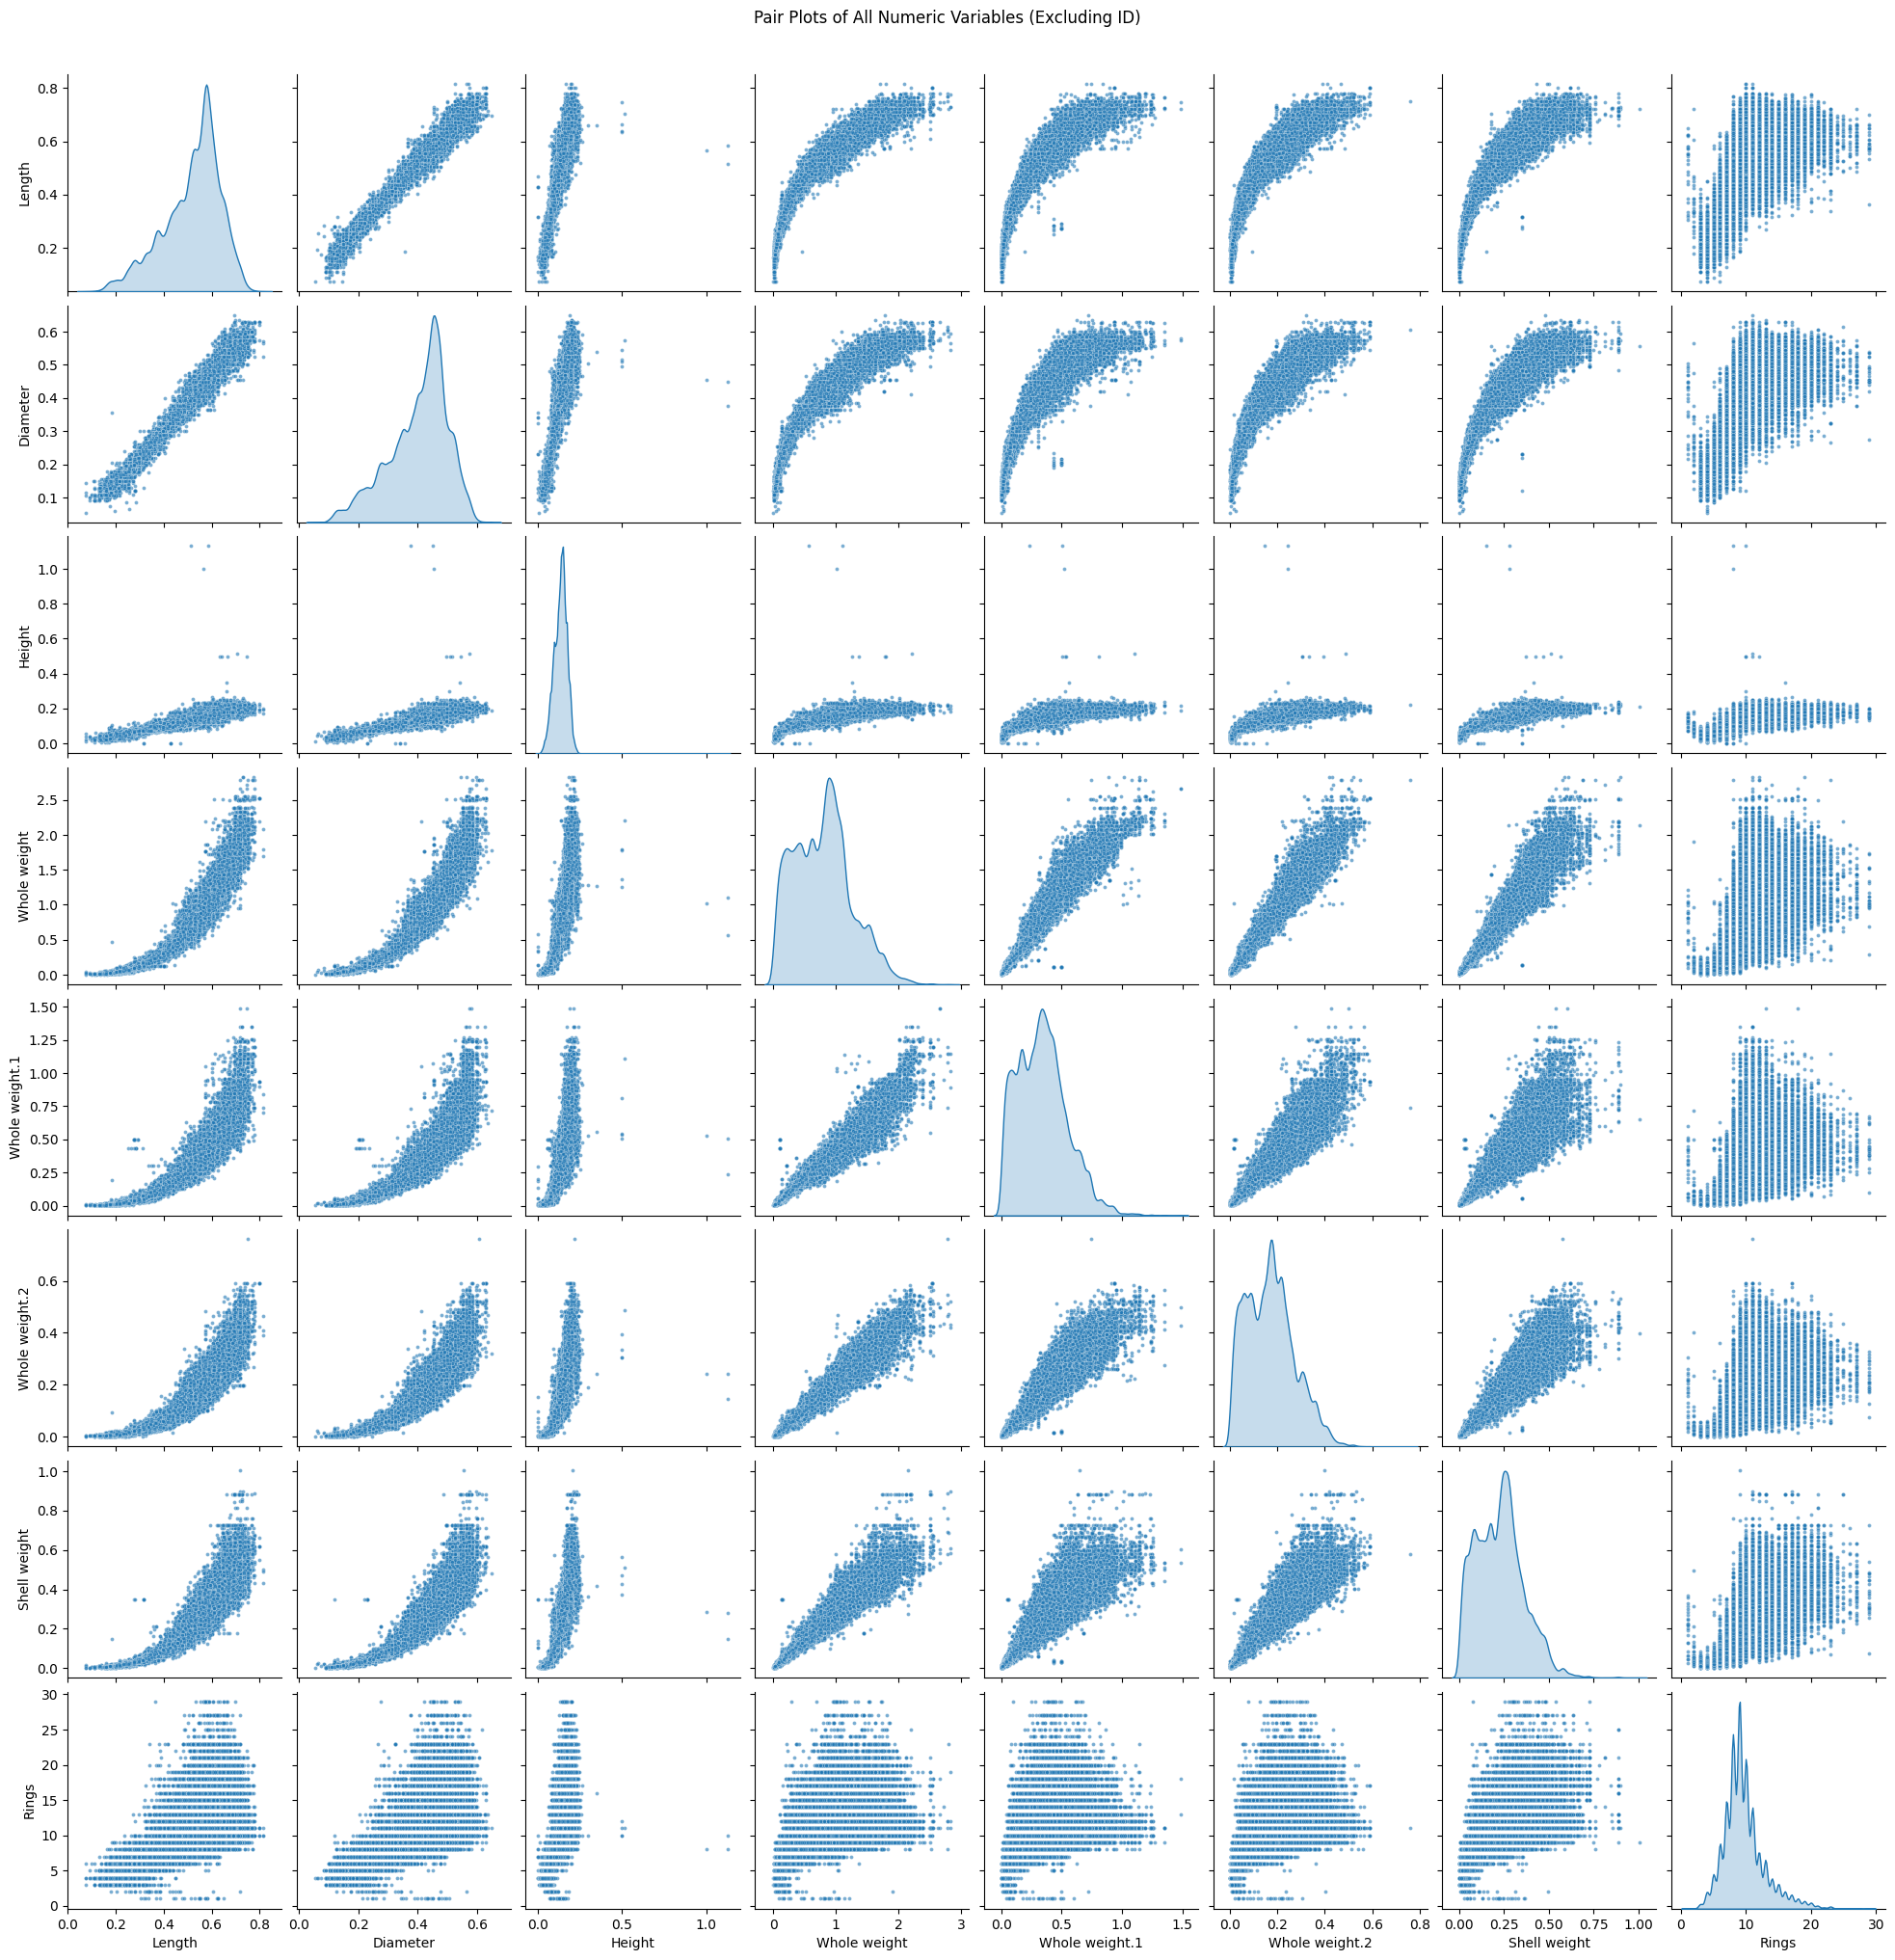


--- Fitting Quadratic Regression ---
Quadratic Model Equation:
Rings = 5.1021 + (25.1103 * Shell_Weight) + (-15.8570 * Shell_Weight^2)

Validation Set Metrics:
Mean Absolute Error (MAE): 1.5947
Root Mean Squared Error (RMSE): 2.2908
Root Mean Squared Log Error (RMSLE): 0.1839


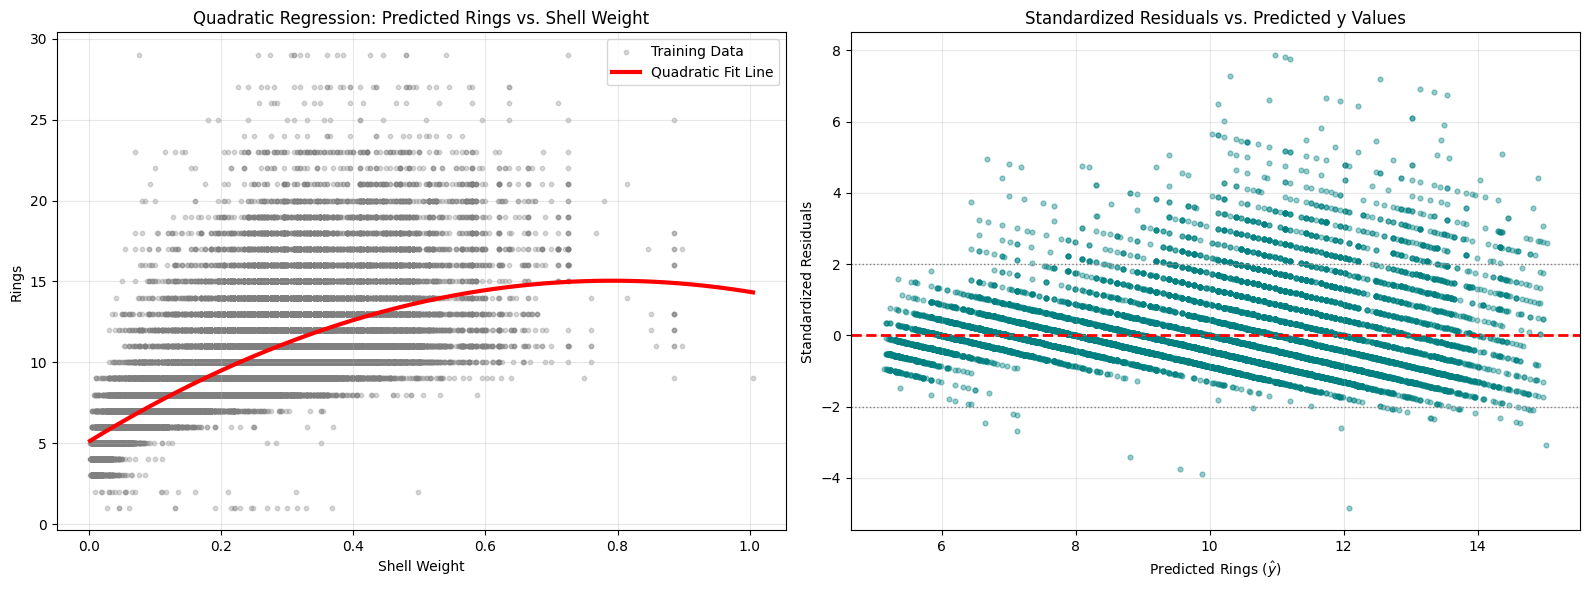

==================== GENERATING KAGGLE SUBMISSION ====================
Generating submission utilizing the Section E Quadratic Regression model...
Successfully generated and saved submission.csv!


/kaggle/working/submission.csv

In [9]:
# The objective is to predict the number of rings in abalone shells.  
# Model 1 (a) of 2:    polynomial reg., spline regression


# Build two models with nonlinearity methods discussed in this week’s lecture and text.   
# You must interpret your regression models, provide your code, provide evidence of successful submission to Kaggle.com.   
# Investigate assumptions, and interpret all of your findings.   


# When ready to submit to Kaggle, go to Abalone home page and click Late Submission. 

# =====================================================================
# A. IMPORT THE TOOLS
# =====================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
import statsmodels.api as sm
from IPython.display import FileLink

# =====================================================================
# B. LOAD THE FILES
# =====================================================================
input_dir = Path("/kaggle/input")

train_files = list(input_dir.rglob("train.csv"))
test_files = list(input_dir.rglob("test.csv"))

print("Training files found:", train_files)
print("Testing files found:", test_files)

train = pd.read_csv(train_files[0])
test = pd.read_csv(test_files[0])

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

# Display the first 5 lines of the dataset
print("\nFirst 5 lines of the training dataset:")
print(train.head())

# =====================================================================
# C. CORRELATION MATRIX & PAIR PLOTS
# =====================================================================
# Select only the numeric columns (dropping non-numeric columns like 'Sex')
numeric_train = train.select_dtypes(include=[np.number])

# Remove the 'id' column from the analysis if it exists
if 'id' in numeric_train.columns:
    numeric_train = numeric_train.drop(columns=['id'])
elif 'Id' in numeric_train.columns:
    numeric_train = numeric_train.drop(columns=['Id'])

# Calculate and display the correlation matrix
correlation_matrix = numeric_train.corr()
print("\nCorrelation Matrix:")
print(correlation_matrix)

# Plot the heatmap for the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap (Excluding ID)")
plt.show()

# Plot each possible pair of numeric variables
print("\nGenerating pair plots for all numeric variables...")
sns.pairplot(numeric_train, diag_kind='kde', plot_kws={'alpha': 0.6, 's': 8})
plt.suptitle("Pair Plots of All Numeric Variables (Excluding ID)", y=1.02)
plt.show()



# =====================================================================
# D. DATA PREPROCESSING
# =====================================================================
# One-hot encode the categorical 'Sex' column
train_encoded = pd.get_dummies(train, columns=['Sex'], drop_first=True)
test_encoded = pd.get_dummies(test, columns=['Sex'], drop_first=True)

# Align test columns with train columns
test_encoded = test_encoded.reindex(columns=[col for col in train_encoded.columns if col != 'Rings'], fill_value=0)

# Define Features (X) and Target (y)
X = train_encoded.drop(columns=['id', 'Rings'], errors='ignore')
y = train_encoded['Rings']
X_test_final = test_encoded.drop(columns=['id'], errors='ignore')

# Local Train-Validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)



# =====================================================================
# E. QUADRATIC REGRESSION (RINGS VS SHELL WEIGHT)
# =====================================================================
print("\n--- Fitting Quadratic Regression ---")

# 1. Prepare the predictor (X) and target (y)
X_sw = numeric_train[['Shell weight']].values
y_rings = numeric_train['Rings'].values

# 2. Split into train and validation sets to investigate fit performance
X_train_sw, X_val_sw, y_train_r, y_val_r = train_test_split(
    X_sw, y_rings, test_size=0.2, random_state=42
)

# 3. Create quadratic features manually: [X, X^2]
X_train_quad = np.hstack((X_train_sw, X_train_sw**2))
X_val_quad = np.hstack((X_val_sw, X_val_sw**2))

# 4. Fit the regression model
quad_model = LinearRegression()
quad_model.fit(X_train_quad, y_train_r)

# 5. Extract and print coefficients for interpretation
intercept = quad_model.intercept_
coef_linear = quad_model.coef_[0]
coef_quad = quad_model.coef_[1]

print(f"Quadratic Model Equation:")
print(f"Rings = {intercept:.4f} + ({coef_linear:.4f} * Shell_Weight) + ({coef_quad:.4f} * Shell_Weight^2)")

# 6. Evaluate performance on the validation set
y_pred_val = quad_model.predict(X_val_quad)
# Ensure no negative or zero values before calculating MSLE/RMSLE
y_pred_val_clipped = np.clip(y_pred_val, 1, None)

mae = mean_absolute_error(y_val_r, y_pred_val_clipped)
rmse = np.sqrt(mean_squared_error(y_val_r, y_pred_val_clipped))
rmsle = np.sqrt(mean_squared_log_error(y_val_r, y_pred_val_clipped))

print(f"\nValidation Set Metrics:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Root Mean Squared Log Error (RMSLE): {rmsle:.4f}")

# 7. Calculate Standardized Residuals for the Validation Set
residuals = y_val_r - y_pred_val
residual_std = np.std(residuals)
standardized_residuals = residuals / residual_std

# 8. Visualizations: Model Fit & Residual Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: The raw data and quadratic curve fit
ax1.scatter(X_train_sw, y_train_r, alpha=0.3, s=10, color='gray', label='Training Data')

x_axis_range = np.linspace(X_sw.min(), X_sw.max(), 500).reshape(-1, 1)
x_axis_quad = np.hstack((x_axis_range, x_axis_range**2))
y_curve_pred = quad_model.predict(x_axis_quad)

ax1.plot(x_axis_range, y_curve_pred, color='red', linewidth=3, label='Quadratic Fit Line')
ax1.set_title("Quadratic Regression: Predicted Rings vs. Shell Weight")
ax1.set_xlabel("Shell Weight")
ax1.set_ylabel("Rings")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Standardized Residuals vs. Predicted Values
ax2.scatter(y_pred_val, standardized_residuals, alpha=0.4, s=12, color='teal')
ax2.axhline(0, color='red', linestyle='--', linewidth=2)
ax2.axhline(2, color='gray', linestyle=':', linewidth=1)
ax2.axhline(-2, color='gray', linestyle=':', linewidth=1)

ax2.set_title("Standardized Residuals vs. Predicted y Values")
# removed ax2.set_xlabel("Predicted Rings ($\hat{y}$)")
ax2.set_xlabel(r"Predicted Rings ($\hat{y}$)")
ax2.set_ylabel("Standardized Residuals")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()





# =====================================================================
# I. CREATE THE KAGGLE LATE SUBMISSION FILE
# =====================================================================
print("="*20 + " GENERATING KAGGLE SUBMISSION " + "="*20)
print("Generating submission utilizing the Section E Quadratic Regression model...")

# 1. Extract the predictor feature from the test dataset
X_test_sw = test[['Shell weight']].values

# 2. Create the exact same quadratic features used during training: [X, X^2]
X_test_quad = np.hstack((X_test_sw, X_test_sw**2))

# 3. Generate predictions on the final test set using the quadratic model
test_predictions = quad_model.predict(X_test_quad)

# 4. Kaggle evaluations don't like negative targets; clip predictions to a minimum of 1 ring
test_predictions = np.clip(test_predictions, 1, None)

# 5. Create the submission DataFrame using your test variable 'test'
# Using an flexible check for id/Id column naming convention
id_col = 'id' if 'id' in test.columns else 'Id'

submission_df = pd.DataFrame({
    id_col: test[id_col],
    'Rings': test_predictions
})

# 6. Save to the CSV file required by the Kaggle environment
submission_df.to_csv('submission.csv', index=False)
print("Successfully generated and saved submission.csv!")

# 7. Display a working download link to the generated CSV file
from IPython.display import FileLink
display(FileLink("submission.csv"))
